# Twitter Sentiment Analysis using Machine Learning

**Objective:** Classify tweets into three sentiment categories: `positive`, `negative`, and `neutral`.

1. Load and inspect the dataset.
2. Explore sentiment distribution and visualize common words.
3. Clean and preprocess tweet text.
4. Split the data into training and testing sets.
5. Fit TF-IDF **only on the training data**.
6. Train and compare four machine-learning models.
7. Evaluate the best-performing model.
8. Predict sentiment for new tweets.



## Import libraries

In [3]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Download required NLTK resources

In [4]:
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## Load the dataset

In [5]:
df = pd.read_csv("tweets.csv")

required_columns = {"text", "sentiment"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (27481, 4)


,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


## Initial data inspection and cleaning

In [6]:
print("Missing values before cleaning:")
display(df[["text", "sentiment"]].isnull().sum())

# Keep rows with both tweet text and sentiment labels.
df = df.dropna(subset=["text", "sentiment"]).copy()

# Normalize text and labels to strings.
df["text"] = df["text"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

print("Dataset shape after removing missing values:", df.shape)
print("\nSentiment labels:")
print(df["sentiment"].value_counts())

Missing values before cleaning:


text         1
sentiment    0
dtype: int64

Dataset shape after removing missing values: (27480, 4)

Sentiment labels:
neutral     11117
positive     8582
negative     7781
Name: sentiment, dtype: int64


## Exploratory Data Analysis (EDA)

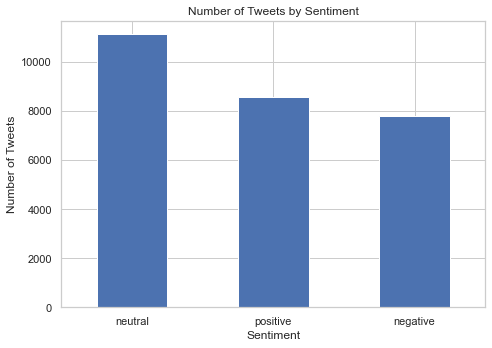

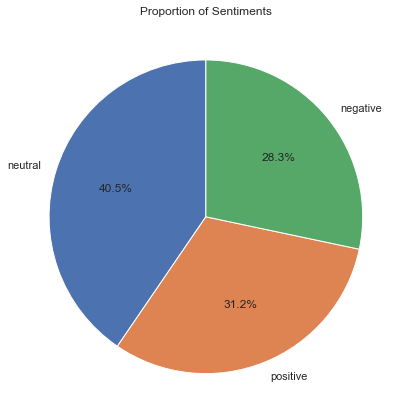

In [7]:
sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")
plt.title("Number of Tweets by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Proportion of Sentiments")
plt.tight_layout()
plt.show()

## Word clouds by sentiment

Word cloud for negative sentiment


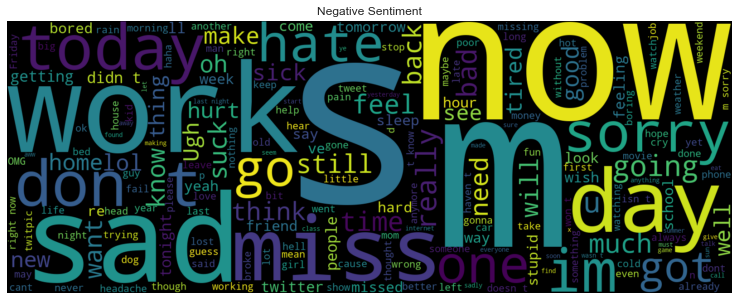

Word cloud for neutral sentiment


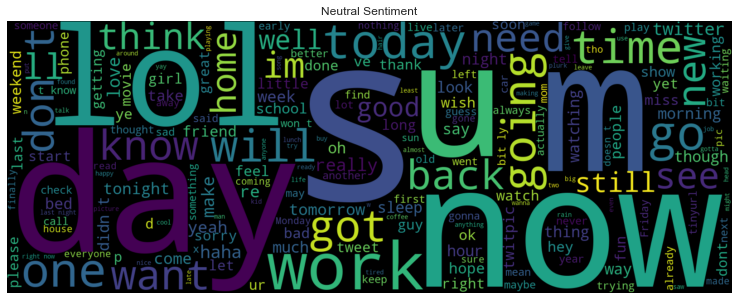

Word cloud for positive sentiment


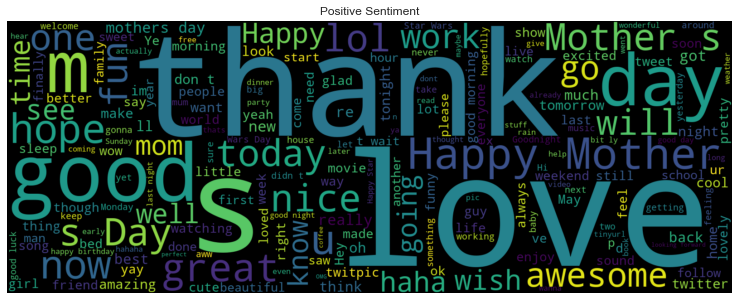

In [8]:
def generate_wordcloud(data, title):
    text = " ".join(data["text"].astype(str))
    # Remove URLs, @mentions, and the RT marker for this visualization.
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"@\\w+|\\bRT\\b", " ", text)

    if not text.strip():
        print(f"No text available for: {title}")
        return

    cloud = WordCloud(
        stopwords=STOPWORDS,
        background_color="black",
        width=1600,
        height=600
    ).generate(text)

    plt.figure(figsize=(14, 5))
    plt.imshow(cloud, interpolation="bilinear")
    plt.title(title)
    plt.axis("off")
    plt.show()

for label in sorted(df["sentiment"].unique()):
    print(f"Word cloud for {label} sentiment")
    generate_wordcloud(df[df["sentiment"] == label], f"{label.title()} Sentiment")

## Text preprocessing

The preprocessing function removes HTML tags and URLs, converts text to lowercase, tokenizes it, removes English stopwords, and applies Porter stemming.

The same function is used for both training data and new user-provided tweets.

In [9]:
# Load stopwords and initialize the stemmer once.
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = str(text)

    # Remove HTML tags and URLs.
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)

    # Keep alphabetic tokens; lowercase before tokenization.
    text = text.lower()
    tokens = word_tokenize(text)

    # Remove stopwords and non-alphabetic tokens, then stem.
    tokens = [
        stemmer.stem(token)
        for token in tokens
        if token.isalpha() and token not in stop_words
    ]

    return " ".join(tokens)

df["cleaned_text"] = df["text"].apply(preprocess_text)

# Remove rows that became empty after preprocessing.
df = df[df["cleaned_text"].str.strip().ne("")].copy()

display(df[["text", "cleaned_text", "sentiment"]].head())

,text,cleaned_text,sentiment
0,"I`d have responded, if I were going",respond go,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,negative
2,my boss is bullying me...,boss bulli,negative
3,what interview! leave me alone,interview leav alon,negative
4,"Sons of ****, why couldn`t they put them on t...",son put releas alreadi bought,negative


## Train-test split

**Important: data leakage prevention**

Split the raw cleaned text and labels before fitting TF-IDF. This ensures that the vocabulary and inverse-document-frequency values are learned only from the training data. The test data is transformed using that already-fitted vectorizer.

In [10]:
X = df["cleaned_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 21899
Testing samples: 5475


## TF-IDF vectorization (fit on training data only)

In [11]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (21899, 15596)
Testing TF-IDF shape: (5475, 15596)


## Train and compare machine-learning models

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

results = []
trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)
    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (weighted)", ascending=False
).reset_index(drop=True)

display(results_df)

Training Logistic Regression...
Training Support Vector Machine...
Training Random Forest...
Training Gradient Boosting...


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Random Forest,0.705023,0.708327,0.705023,0.704550
1,Support Vector Machine,0.699909,0.716882,0.699909,0.699095
2,Logistic Regression,0.694612,0.703304,0.694612,0.694989
3,Gradient Boosting,0.649863,0.687352,0.649863,0.642604


## Model comparison

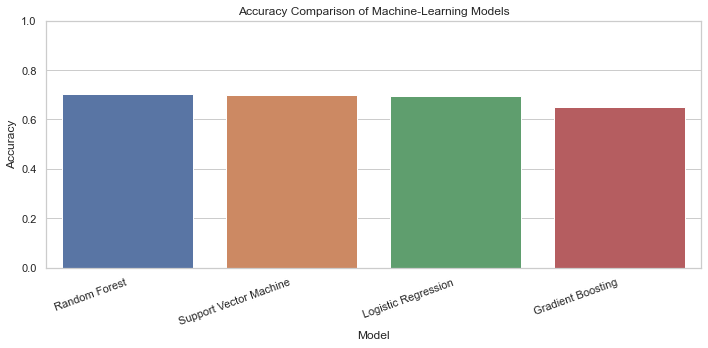

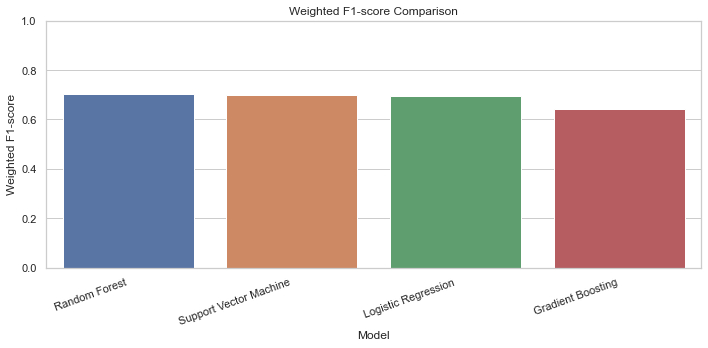

In [13]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Accuracy Comparison of Machine-Learning Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="F1-score (weighted)")
plt.title("Weighted F1-score Comparison")
plt.xlabel("Model")
plt.ylabel("Weighted F1-score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Select the best model

The best model is selected automatically using **weighted F1-score**, which balances precision and recall while accounting for class sizes. The selected model is then used consistently for evaluation and new-tweet predictions.

In [14]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("Best weighted F1-score:", round(results_df.loc[0, "F1-score (weighted)"], 4))

Best model: Random Forest
Best weighted F1-score: 0.7045


## 13. Evaluate the selected model

Classification Report - Random Forest
              precision    recall  f1-score   support

    negative       0.73      0.62      0.67      1555
     neutral       0.66      0.73      0.69      2204
    positive       0.76      0.75      0.75      1716

    accuracy                           0.71      5475
   macro avg       0.71      0.70      0.70      5475
weighted avg       0.71      0.71      0.70      5475



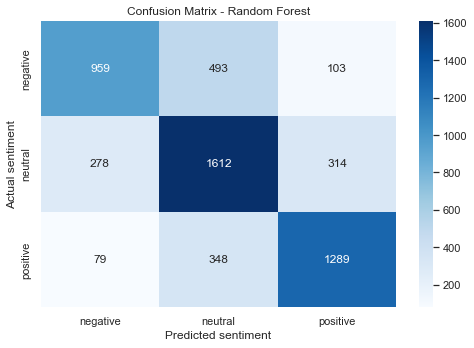

In [15]:
y_pred = best_model.predict(X_test_tfidf)

print(f"Classification Report - {best_model_name}")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

## Test your own tweets

In [16]:
new_tweets = [
    "I hate Twitter",
    "The weather is awesome today!",
    "I am using Twitter this morning."
]

cleaned_tweets = [preprocess_text(tweet) for tweet in new_tweets]
new_tweets_tfidf = tfidf_vectorizer.transform(cleaned_tweets)
predicted_sentiments = best_model.predict(new_tweets_tfidf)

for tweet, sentiment in zip(new_tweets, predicted_sentiments):
    print(f"Tweet: {tweet}")
    print(f"Predicted sentiment: {sentiment}")
    print("-" * 60)

Tweet: I hate Twitter
Predicted sentiment: negative
------------------------------------------------------------
Tweet: The weather is awesome today!
Predicted sentiment: positive
------------------------------------------------------------
Tweet: I am using Twitter this morning.
Predicted sentiment: neutral
------------------------------------------------------------


## Conclusion

In [17]:
print(
    f"The models were evaluated on a held-out test set. "
    f"{best_model_name} achieved the highest weighted F1-score "
    f"among the models tested ({results_df.loc[0, 'F1-score (weighted)']:.4f})."
)

The models were evaluated on a held-out test set. Random Forest achieved the highest weighted F1-score among the models tested (0.7045).


This project demonstrates a complete text-classification workflow for Twitter sentiment analysis. It includes exploratory data analysis, text preprocessing, TF-IDF feature extraction, model comparison, evaluation, and prediction on new tweets.

